<a href="https://colab.research.google.com/github/fat-panda-wasib/Logistics-operations-supply-chain---Project-Work/blob/main/Logistics_Project_Work.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Logistics, operations & supply chain - Project Work**

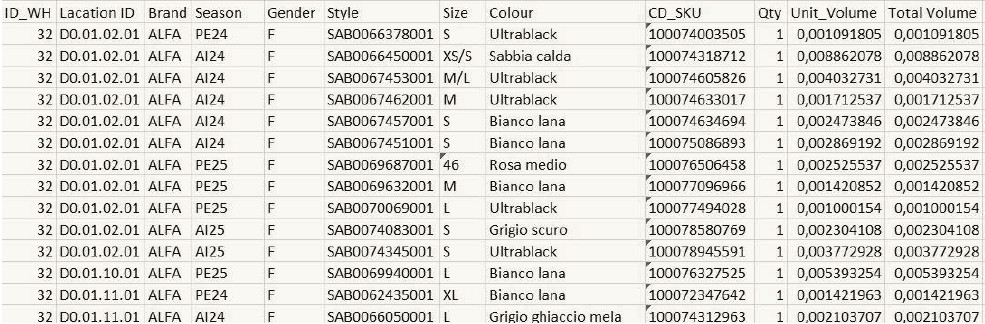
## Objective: Defining the best procedure to obtain the minimum cost of picking.
## Constraints: each box need to be made by Season-Gender.
## Box Dimensions: 60X40X40
## Cost of Picking by location: 0.40 €
## Cost of Picking by item: 0.35 €

In the following we import the pandas library. Then we define a string variable named file_path. It stores the full path to a CSV file.

In [ ]:
import pandas as pd

# Define the file path. In Colab, you can typically access uploaded files directly.
file_path = '/content/sample_data/ProjectWorkDataBase (1).csv'

In the following part, we load our data file and give a quick first look. It tries to open the file and, if successful, shows a small sample of the data, lists what kind of information each column holds, and provides basic statistics for the numbers in our dataset.

In [ ]:
# Load the data, specifying the correct delimiter and decimal separator.
try:
    df = pd.read_csv(file_path, delimiter=';', decimal=',')
    print("✅ Data loaded successfully.")
except FileNotFoundError:
    print(f"Error: File not found at {file_path}. Please ensure '{file_path}' is uploaded to your Colab session.")
    df = None # Set df to None in case of error

if df is not None:
    # --- Initial Exploration ---

    # 1. Display the first 5 rows to verify correct loading and structure
    print("\n" + "="*50)
    print("1. DataFrame Head (First 5 Rows)")
    print("="*50)
    print(df.head())

    # 2. Display column names, data types, and non-null counts
    print("\n" + "="*50)
    print("2. DataFrame Info (Column Types & Missing Data)")
    print("="*50)
    df.info()

    # 3. Display descriptive statistics for numeric columns
    print("\n" + "="*50)
    print("3. Descriptive Statistics")
    print("="*50)
    # Exclude Sku from describe as it's an ID, not a measurement
    print(df.drop(columns=['Sku']).describe())

/tmp/ipython-input-1973079809.py:3: DtypeWarning: Columns (10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path, delimiter=';', decimal=',')


✅ Data loaded successfully.

1. DataFrame Head (First 5 Rows)
   WH_Id       Loc_Id Brand Season Gender          Style  Size        Colour  \
0     32  D0.01.02.01  Alfa   PE24      F  SAB0066378001     S    Ultrablack   
1     32  D0.01.02.01  Alfa   AI24      F  SAB0066450001  XS/S  Sabbia calda   
2     32  D0.01.02.01  Alfa   AI24      F  SAB0067453001   M/L    Ultrablack   
3     32  D0.01.02.01  Alfa   AI24      F  SAB0067462001     M    Ultrablack   
4     32  D0.01.02.01  Alfa   AI24      F  SAB0067457001     S   Bianco lana   

            Sku  Qty  Vol_Unit VolTotale  
0  100074003505    1  0.001092  0.001092  
1  100074318712    1  0.008862  0.008862  
2  100074605826    1  0.004033  0.004033  
3  100074633017    1  0.001713  0.001713  
4  100074634694    1  0.002474  0.002474  

2. DataFrame Info (Column Types & Missing Data)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 170011 entries, 0 to 170010
Data columns (total 12 columns):
 #   Column     Non-Null Count   Dtype 

In the following part, we fix the format of our number columns so they can be used for calculations. It converts the quantity and volume columns into proper numbers. If any values can't be converted (like text or blanks), they're removed. It then cleans out any rows that are still missing these essential numbers and tells you how many rows were removed in the process.

In [ ]:
# 1. Handle Data Types
# Ensure numeric columns are correctly typed. 'Int64' is used for Qty to handle potential NaNs if they arise.
df['Qty'] = pd.to_numeric(df['Qty'], errors='coerce').astype('Int64')
df['Vol_Unit'] = pd.to_numeric(df['Vol_Unit'], errors='coerce')
df['VolTotale'] = pd.to_numeric(df['VolTotale'], errors='coerce')

# Drop rows where critical numeric columns resulted in NaN after conversion (unlikely, but robust)
initial_rows = len(df)
df.dropna(subset=['Qty', 'Vol_Unit', 'VolTotale'], inplace=True)
print(f"Rows removed due to missing critical numeric data (Qty/Volume): {initial_rows - len(df)}")

Rows removed due to missing critical numeric data (Qty/Volume): 65536


In the following cell, we clean our data by removing any exact duplicate rows.

In [ ]:
# 2. Remove Duplicates
initial_duplicates = df.duplicated().sum()
df.drop_duplicates(inplace=True)
print(f"Removed {initial_duplicates} duplicate rows.")

Removed 0 duplicate rows.


This cell makes sure our text categories are consistent. It cleans up the 'Season', 'Gender', and 'Brand' columns by removing extra spaces and converting everything to uppercase. This prevents the same value (like "summer" and "SUMMER") from being treated as different categories, making your analysis more accurate.

In [ ]:
# 3. Standardize Categorical Variables
# Focusing on key variables for the project (Season and Gender)
categorical_cols = ['Season', 'Gender', 'Brand']

for col in categorical_cols:
    # Strip whitespace, convert to uppercase, and handle non-string types
    if df[col].dtype == 'object' or df[col].dtype.name == 'category':
        # Convert to string first to apply string methods safely
        df[col] = df[col].astype(str).str.strip().str.upper()

This cell gives us a final check on our cleaned data. It shows how much data remains, confirms our categories are now consistent, and verifies that our number columns are ready for analysis.

In [ ]:
# --- Final Check ---
print("\n--- Cleaned DataFrame Status ---")
print(f"Final DataFrame shape: {df.shape}")
print("\nStandardized Season values (Top 5):")
print(df['Season'].value_counts().head())
print("\nStandardized Gender values:")
print(df['Gender'].value_counts())
print("\nDataFrame dtypes after cleaning (relevant columns):")
print(df[['Qty', 'Vol_Unit', 'VolTotale', 'Season', 'Gender']].dtypes)

# Save the cleaned DataFrame for the next steps
df.to_csv('cleaned_project_data.csv', index=False, sep=';')
print("\nCleaned data saved to 'cleaned_project_data.csv'.")


--- Cleaned DataFrame Status ---
Final DataFrame shape: (104475, 12)

Standardized Season values (Top 5):
Season
AI24    42397
PE25    30452
AI25    16785
PE24     7802
PE26     7039
Name: count, dtype: int64

Standardized Gender values:
Gender
F    82762
M    19617
A     1378
B      718
Name: count, dtype: int64

DataFrame dtypes after cleaning (relevant columns):
Qty            Int64
Vol_Unit     float64
VolTotale    float64
Season        object
Gender        object
dtype: object

Cleaned data saved to 'cleaned_project_data.csv'.


This cell organizes our season information by creating two new, useful columns. It extracts the full year (like 2024) from our season codes and sorts each season into a simple Spring/Summer or Fall/Winter category. This makes our data easier to analyze for trends over time and by season type.

In [ ]:
# --- 1 & 2. Season Engineering ---
# Season codes example: PE24, AI25. PE/ES = Spring/Summer, AI/IN = Fall/Winter
# Extract Year (last two characters)
df['Season_Year'] = df['Season'].str[-2:].astype(int) + 2000

# Identify Season Type (first two characters)
def get_season_type(season_code):
    prefix = season_code[:2]
    if prefix in ['PE', 'ES']: # Primavera/Estate (Spring/Summer)
        return 'SS'
    elif prefix in ['AI', 'IN']: # Autunno/Inverno (Fall/Winter)
        return 'FW'
    else:
        return 'OTHER'

df['Season_Type'] = df['Season'].apply(get_season_type)

This cell simply changes the column name from "VolTotale" to the more descriptive "LineItem_Volume". The change is made directly in our main dataset.

In [ ]:
# --- 3. Total Volume Metrics ---
# Rename VolTotale for clarity (it represents the total volume for that line item)
df.rename(columns={'VolTotale': 'LineItem_Volume'}, inplace=True)

This cell breaks down location codes like 'D0.01.02.01' into separate, easier-to-use parts. It creates four new columns for each level of the location hierarchy, converting them to numbers where possible. This makes it simpler to analyze and filter your data by specific location levels.

In [ ]:
# --- 4. Parses Location Hierarchy ---
# Loc_Id format: D0.01.02.01 (4 levels separated by dots)
location_parts = df['Loc_Id'].str.split('.', expand=True)

# Assuming the standard 4-level hierarchy is always present
if location_parts.shape[1] >= 4:
    df['Loc_Level1'] = location_parts[0] # e.g., D0, D1, D2
    # Convert subsequent levels to integer for proper sorting/analysis
    df['Loc_Level2'] = pd.to_numeric(location_parts[1], errors='coerce').astype('Int64')
    df['Loc_Level3'] = pd.to_numeric(location_parts[2], errors='coerce').astype('Int64')
    df['Loc_Level4'] = pd.to_numeric(location_parts[3], errors='coerce').astype('Int64')
    # Note: We keep Loc_Id as the unique identifier

This cell gives us a final overview of our enhanced dataset. It shows a preview of our new season and location columns, displays the final size of our data, and then saves the complete dataset with all its new features to a file called "engineered_project_data.csv."

In [ ]:
# --- Final Check & Saving ---
print("--- Feature Engineering Summary ---")
print(f"New Season columns:")
print(df[['Season', 'Season_Year', 'Season_Type']].head())
print("\nNew Location columns:")
print(df[['Loc_Id', 'Loc_Level1', 'Loc_Level2', 'Loc_Level3', 'Loc_Level4']].head())
print(f"\nDataFrame shape after feature engineering: {df.shape}")

# Save the DataFrame
df.to_csv('engineered_project_data.csv', index=False, sep=';')
print("\nEngineered data saved to 'engineered_project_data.csv'.")

--- Feature Engineering Summary ---
New Season columns:
  Season  Season_Year Season_Type
0   PE24         2024          SS
1   AI24         2024          FW
2   AI24         2024          FW
3   AI24         2024          FW
4   AI24         2024          FW

New Location columns:
        Loc_Id Loc_Level1  Loc_Level2  Loc_Level3  Loc_Level4
0  D0.01.02.01         D0           1           2           1
1  D0.01.02.01         D0           1           2           1
2  D0.01.02.01         D0           1           2           1
3  D0.01.02.01         D0           1           2           1
4  D0.01.02.01         D0           1           2           1

DataFrame shape after feature engineering: (104475, 18)

Engineered data saved to 'engineered_project_data.csv'.


This cell sets up everything needed for creating charts. It prepares our number columns for analysis, sets a clean visual style for the graphs, and creates a handy function that automatically saves any chart we make with a given filename.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Convert Loc_Level2, Loc_Level3, Loc_Level4 back to int for proper analysis
for col in ['Loc_Level2', 'Loc_Level3', 'Loc_Level4']:
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)

sns.set_style("whitegrid")

# Define a function to generate and save plots
def save_plot(fig, filename):
    plt.tight_layout()
    fig.savefig(filename)
    plt.close(fig)
    print(f"Saved: {filename}")

This cell creates a chart showing how often different order quantities appear, focusing on quantities of 10 or less (since these are most common). The chart is saved as an image file for you to use later.

In [ ]:
# 1. Quantity Distribution (Histogram)
# Filter for Qty <= 10 as most items will have small quantities.
fig1, ax1 = plt.subplots(figsize=(10, 6))
df[df['Qty'] <= 10]['Qty'].plot(kind='hist', bins=10, ax=ax1, edgecolor='black', color='skyblue')
ax1.set_title('1. Distribution of Order Quantity (Qty ≤ 10)', fontsize=14)
ax1.set_xlabel('Quantity (Qty)', fontsize=12)
ax1.set_ylabel('Number of Line Items', fontsize=12)
ax1.set_xticks(range(1, 11))
save_plot(fig1, 'eda_qty_distribution.png')

Saved: eda_qty_distribution.png


This cell creates a bar chart comparing total order quantities between different genders. It shows which gender accounts for the most sales volume and saves the chart as an image.

In [ ]:
# 2. Gender Distribution (Bar Chart - Total Quantity)
gender_qty = df.groupby('Gender')['Qty'].sum().sort_values(ascending=False)
fig2, ax2 = plt.subplots(figsize=(8, 6))
gender_qty.plot(kind='bar', ax=ax2, color='coral')
ax2.set_title('2. Total Quantity (Qty) by Gender', fontsize=14)
ax2.set_xlabel('Gender', fontsize=12)
ax2.set_ylabel('Total Quantity', fontsize=12)
plt.xticks(rotation=0)
save_plot(fig2, 'eda_gender_distribution.png')

Saved: eda_gender_distribution.png


This cell analyzes the number of orders across years and seasons. It creates a stacked bar chart that shows, for each year, how many orders belong to Spring/Summer versus Fall/Winter. The chart is saved as an image file.

In [ ]:
# 3. Season Analysis - Season Type by Year (Stacked Bar)
season_analysis = df.groupby(['Season_Year', 'Season_Type']).size().unstack(fill_value=0)
fig3, ax3 = plt.subplots(figsize=(10, 6))
season_analysis.plot(kind='bar', stacked=True, ax=ax3, colormap='viridis')
ax3.set_title('3. Line Item Count by Season Type and Year', fontsize=14)
ax3.set_xlabel('Season Year', fontsize=12)
ax3.set_ylabel('Total Line Item Count', fontsize=12)
ax3.legend(title='Season Type', loc='upper left')
plt.xticks(rotation=0)
save_plot(fig3, 'eda_season_year_stacked.png')

Saved: eda_season_year_stacked.png


This cell compares total order quantities between the Spring/Summer and Fall/Winner seasons. It creates a simple bar chart showing which season type generates more sales volume and saves it as an image.

In [ ]:
# 4. Season Analysis - Total Quantity by Season Type
season_type_qty = df.groupby('Season_Type')['Qty'].sum().sort_values(ascending=False)
fig4, ax4 = plt.subplots(figsize=(8, 6))
season_type_qty.plot(kind='bar', ax=ax4, color=['darkgreen', 'darkred', 'gray'])
ax4.set_title('4. Total Quantity (Qty) by Season Type (SS/FW)', fontsize=14)
ax4.set_xlabel('Season Type', fontsize=12)
ax4.set_ylabel('Total Quantity', fontsize=12)
plt.xticks(rotation=0)
save_plot(fig4, 'eda_season_type_qty.png')

Saved: eda_season_type_qty.png


This cell identifies the 10 most popular colors in our data. It creates a colorful bar chart showing how many items were ordered for each of these top colors and saves it as an image.

In [ ]:
# 5. Color Popularity (Top 10)
top_n = 10
color_counts = df['Colour'].value_counts().nlargest(top_n)
fig5, ax5 = plt.subplots(figsize=(10, 6))
color_counts.plot(kind='bar', ax=ax5, color=sns.color_palette("Spectral", top_n))
ax5.set_title(f'5. Top {top_n} Most Popular Colors (Line Item Count)', fontsize=14)
ax5.set_xlabel('Color', fontsize=12)
ax5.set_ylabel('Line Item Count', fontsize=12)
plt.xticks(rotation=45, ha='right')
save_plot(fig5, 'eda_color_popularity.png')

Saved: eda_color_popularity.png


This cell finds the 15 most common product sizes in our data. It creates a soft-colored bar chart showing how often each size appears and saves it as an image.

In [ ]:
# 6. Size Distribution (Top 15)
top_n = 15
size_counts = df['Size'].value_counts().nlargest(top_n)
fig6, ax6 = plt.subplots(figsize=(10, 6))
size_counts.plot(kind='bar', ax=ax6, color=sns.color_palette("pastel", top_n))
ax6.set_title(f'6. Top {top_n} Size Distribution (Line Item Count)', fontsize=14)
ax6.set_xlabel('Size', fontsize=12)
ax6.set_ylabel('Line Item Count', fontsize=12)
plt.xticks(rotation=45, ha='right')
save_plot(fig6, 'eda_size_distribution.png')

Saved: eda_size_distribution.png


This cell analyzes which warehouse areas handle the most orders. It creates a chart showing total quantities picked for each main location, highlighting the busiest zones, and saves the chart as an image.

In [ ]:
# 7. Warehouse Utilization (Loc_Level1 - Total Quantity)
loc_level1_qty = df.groupby('Loc_Level1')['Qty'].sum().sort_values(ascending=False)
fig7, ax7 = plt.subplots(figsize=(8, 6))
loc_level1_qty.plot(kind='bar', ax=ax7, color='teal')
ax7.set_title('7. Warehouse Utilization by Loc Level 1 (Total Quantity Picked)', fontsize=14)
ax7.set_xlabel('Location Level 1', fontsize=12)
ax7.set_ylabel('Total Quantity Picked', fontsize=12)
plt.xticks(rotation=0)
save_plot(fig7, 'eda_loc_level1_utilization.png')

Saved: eda_loc_level1_utilization.png


This cell identifies the 10 most active specific locations in the warehouse. It creates a chart showing which exact spots handle the most order quantities and saves it as an image.

In [ ]:
# 8. Warehouse Utilization (Top 10 Loc_Id - Total Quantity)
loc_id_qty = df.groupby('Loc_Id')['Qty'].sum().nlargest(10).sort_values(ascending=False)
fig8, ax8 = plt.subplots(figsize=(12, 6))
loc_id_qty.plot(kind='bar', ax=ax8, color='purple')
ax8.set_title('8. Top 10 Specific Locations (Loc_Id) by Total Quantity Picked', fontsize=14)
ax8.set_xlabel('Location ID (Loc_Id)', fontsize=12)
ax8.set_ylabel('Total Quantity Picked', fontsize=12)
plt.xticks(rotation=45, ha='right')
save_plot(fig8, 'eda_loc_id_top10_utilization.png')

Saved: eda_loc_id_top10_utilization.png


This cell creates a chart showing how common different package volumes are, focusing on smaller items under 0.1 m³. The chart is saved as an image.

In [ ]:
# 9. Volume Distribution (Histogram)
fig9, ax9 = plt.subplots(figsize=(10, 6))
# Filter volume to be less than 0.1 m³ for better visualization of the dense area.
df[df['LineItem_Volume'] < 0.1]['LineItem_Volume'].plot(kind='hist', bins=50, ax=ax9, edgecolor='black', color='darkblue')
# FIX: Use raw string for LaTeX title
ax9.set_title(r'9. Distribution of Line Item Volume ($< 0.1\,m^3$)', fontsize=14)
ax9.set_xlabel(r'Line Item Volume ($m^3$)', fontsize=12)
ax9.set_ylabel('Number of Line Items', fontsize=12)
save_plot(fig9, 'eda_volume_distribution.png')

Saved: eda_volume_distribution.png


This cell analyzes the total volume of shipments for Spring/Summer versus Fall/Winter seasons. It creates a bar chart comparing which season moves more physical volume and saves the chart as an image

In [ ]:
# 1. Volume analysis by season (Total Volume by Season_Type)
volume_by_season = df.groupby('Season_Type')['LineItem_Volume'].sum().sort_values(ascending=False)
fig1, ax1 = plt.subplots(figsize=(8, 6))
volume_by_season.plot(kind='bar', ax=ax1, color=['darkcyan', 'darkorange', 'gray'])
ax1.set_title(r'1. Total Volume by Season Type ($m^3$)', fontsize=14)
ax1.set_xlabel('Season Type', fontsize=12)
ax1.set_ylabel(r'Total Line Item Volume ($m^3$)', fontsize=12)
plt.xticks(rotation=0)
save_plot(fig1, 'adv_volume_by_season.png')

Saved: adv_volume_by_season.png


This cell finds the 10 most popular product styles based on total orders. It creates a bar chart showing which styles sell the most and saves it as an image.

In [ ]:
# 2. Most common styles (Top 10 Styles by Total Quantity)
top_n = 10
style_qty = df.groupby('Style')['Qty'].sum().nlargest(top_n).sort_values(ascending=False)
fig2, ax2 = plt.subplots(figsize=(12, 6))
style_qty.plot(kind='bar', ax=ax2, color=sns.color_palette("rocket", top_n))
ax2.set_title(f'2. Top {top_n} Most Common Styles (by Total Quantity Picked)', fontsize=14)
ax2.set_xlabel('Style', fontsize=12)
ax2.set_ylabel('Total Quantity Picked', fontsize=12)
plt.xticks(rotation=45, ha='right')
save_plot(fig2, 'adv_most_common_styles.png')

Saved: adv_most_common_styles.png


This cell creates a chart showing how order quantities break down by both season type and gender. For Spring/Summer and Fall/Winter, it shows what portion of total sales comes from each gender category, saving the result as an image.

In [ ]:
# 3. Gender distribution across seasons (Stacked Bar of Total Qty)
gender_season_qty = df.groupby(['Season_Type', 'Gender'])['Qty'].sum().unstack(fill_value=0)
# Reorder columns to put major genders first
# Ensure all possible gender columns are handled gracefully
gender_cols = [col for col in ['F', 'M', 'A', 'B'] if col in gender_season_qty.columns]
if gender_cols:
    gender_season_qty = gender_season_qty[gender_cols]

fig3, ax3 = plt.subplots(figsize=(10, 6))
gender_season_qty.plot(kind='bar', stacked=True, ax=ax3, colormap='tab10')
ax3.set_title('3. Gender Distribution of Total Quantity Across Season Types', fontsize=14)
ax3.set_xlabel('Season Type', fontsize=12)
ax3.set_ylabel('Total Quantity Picked', fontsize=12)
ax3.legend(title='Gender')
plt.xticks(rotation=0)
save_plot(fig3, 'adv_gender_across_seasons.png')

Saved: adv_gender_across_seasons.png


This cell analyzes which second-level warehouse areas (like aisles or sections) handle the most orders. It finds the top 10 busiest areas, creates a chart to show their volume, and saves it as an image.

In [ ]:
# 4. Location-based analysis (Total Qty by Loc_Level2)
# Ensure Loc_Level2 is numeric for proper sorting/grouping, handling any leftover non-numeric data gracefully.
df['Loc_Level2'] = pd.to_numeric(df['Loc_Level2'], errors='coerce')
loc_level2_qty = df.groupby('Loc_Level2')['Qty'].sum().sort_values(ascending=False).head(10)
fig4, ax4 = plt.subplots(figsize=(10, 6))
loc_level2_qty.plot(kind='bar', ax=ax4, color='darkmagenta')
ax4.set_title('4. Top 10 Location Level 2 by Total Quantity Picked', fontsize=14)
ax4.set_xlabel('Location Level 2', fontsize=12)
ax4.set_ylabel('Total Quantity Picked', fontsize=12)
plt.xticks(rotation=0) # Changed to 0 for better readability of integers
save_plot(fig4, 'adv_loc_level2_analysis.png')

Saved: adv_loc_level2_analysis.png


This cell identifies the 5 favorite colors among female customers. It creates a chart showing which colors women buy most and saves it as an image.

In [ ]:
# 5. Color preferences by gender (Top 5 Colors for Female (F))
df_f = df[df['Gender'] == 'F']
top_n = 5
color_by_f = df_f.groupby('Colour')['Qty'].sum().nlargest(top_n).sort_values(ascending=False)
fig5, ax5 = plt.subplots(figsize=(8, 6))
color_by_f.plot(kind='bar', ax=ax5, color=sns.color_palette("RdYlBu", top_n))
ax5.set_title(f'5. Top {top_n} Color Preferences by Total Quantity (Gender: F)', fontsize=14)
ax5.set_xlabel('Color', fontsize=12)
ax5.set_ylabel('Total Quantity Picked', fontsize=12)
plt.xticks(rotation=45, ha='right')
save_plot(fig5, 'adv_color_by_gender_f.png')

Saved: adv_color_by_gender_f.png


This cell sets up the basic pricing rules for our logistics costs. It defines: the volume of a standard shipping box, a fee for each warehouse location visited, and a fee for each item picked.

In [ ]:
# Box dimensions and volume (60 x 40 x 40 cm = 0.096 m^3)
BOX_VOLUME_M3 = 0.6 * 0.4 * 0.4 # 0.096 m^3

# Picking Costs
COST_PER_LOCATION = 0.40 # €
COST_PER_ITEM = 0.35 # €

This cell loads our previously cleaned and organized dataset from its file so you can begin calculating logistics costs.

In [ ]:
# 1. Load the engineered data
df = pd.read_csv('/content/engineered_project_data.csv', delimiter=';')

This cell prepares our data for cost calculation. It groups items by their season, gender, and the specific warehouse location they come from, tallying up the total number of unique products, total quantity, and total volume for each group. This step simulates how items are collected when assembling an order.

In [ ]:
# --- 2. Aggregation by Box Constraint (Season-Gender) and Location (Loc_Id) ---

# This grouping simulates the cost impact of picking multiple SKUs at one Loc_Id for a specific Season-Gender box.
df_agg_loc = df.groupby(['Season', 'Gender', 'Loc_Id']).agg(
    SKU_Count=('Sku', 'nunique'),
    Total_Qty_Loc=('Qty', 'sum'),
    Total_Volume_Loc=('LineItem_Volume', 'sum')
).reset_index()

This cell calculates the picking cost for each warehouse stop. It adds two components: a flat fee for visiting a location and an item-based fee for each unique product picked there. The result is the total cost for that specific stop.

In [ ]:
# --- 3. Calculate Picking Costs per Location Visit (Base Cost Model) ---

# Location Cost: 0.40 € per unique Loc_Id visit
df_agg_loc['Location_Cost'] = COST_PER_LOCATION

# Item Pick Cost: 0.35 € per unique item (SKU) picked at that location
df_agg_loc['Item_Pick_Cost'] = df_agg_loc['SKU_Count'] * COST_PER_ITEM

# Total Picking Cost for one location stop (the total cost that location contributes to the box group)
df_agg_loc['Total_Picking_Cost_Loc'] = df_agg_loc['Location_Cost'] + df_agg_loc['Item_Pick_Cost']

This cell rolls up all the costs and totals for each season-and-gender order group. It calculates the total number of locations visited, total unique items, total quantity, total volume, and the total picking cost for the entire order.

In [ ]:
# --- 4. Aggregate to Box Level (Season-Gender Group) ---

# Sum up all location-based costs and metrics for the final box constraint group.
df_agg_box = df_agg_loc.groupby(['Season', 'Gender']).agg(
    Total_Locations=('Loc_Id', 'nunique'),
    Total_SKUs=('SKU_Count', 'sum'),
    Total_Quantity=('Total_Qty_Loc', 'sum'),
    Total_Volume_Group=('Total_Volume_Loc', 'sum'),
    Total_Picking_Cost_Group=('Total_Picking_Cost_Loc', 'sum')
).reset_index()

This cell determines how many shipping boxes are needed for each order group. It divides the total volume of items by the capacity of a single box and always rounds up, because you can't ship a partial box.

In [ ]:
import numpy as np

# --- 5. Simulate Minimum Box Requirements (Based on Volume) ---

# Calculate the minimum number of boxes required based on volume (using ceiling function)
df_agg_box['Minimum_Boxes_Volume'] = np.ceil(df_agg_box['Total_Volume_Group'] / BOX_VOLUME_M3).astype(int)

This cell finalizes the cost analysis. It calculates the average cost per item and per box for each order group, then sorts all groups from most expensive to cheapest to make the results easy to review.

In [ ]:
# --- 6. Final Analysis & Presentation ---

# Calculate average metrics per item and per box
df_agg_box['Avg_Cost_Per_Item'] = df_agg_box['Total_Picking_Cost_Group'] / df_agg_box['Total_SKUs']
df_agg_box['Avg_Cost_Per_Box'] = df_agg_box['Total_Picking_Cost_Group'] / df_agg_box['Minimum_Boxes_Volume']

# Sort by Total Cost for visualization
df_final_cost = df_agg_box.sort_values(by='Total_Picking_Cost_Group', ascending=False)

This cell improves the cost report by giving the columns clearer names like "Total Picking Cost (€)" instead of technical abbreviations. The changes are made directly to your final summary table.

In [ ]:
# Rename columns for final presentation
df_final_cost.rename(columns={
    'Total_Picking_Cost_Group': 'Total Picking Cost (€)',
    'Total_Locations': 'Total Location Visits',
    'Total_SKUs': 'Total Items (SKUs)',
    'Total_Volume_Group': 'Total Volume (m^3)',
    'Minimum_Boxes_Volume': 'Min Boxes (Vol)',
    'Avg_Cost_Per_Item': 'Avg Cost per Item (€)',
    'Avg_Cost_Per_Box': 'Avg Cost per Box (€)'
}, inplace=True)

This cell cleans up the final report by keeping only the most important columns, like season, gender, total cost, and volume. It removes any extra data to give you a clear and focused summary.

In [ ]:
# Select and format the key columns
columns_to_show = [
    'Season', 'Gender', 'Total Items (SKUs)', 'Total Location Visits',
    'Total Picking Cost (€)', 'Total Volume (m^3)', 'Min Boxes (Vol)',
    'Avg Cost per Item (€)', 'Avg Cost per Box (€)'
]
df_final_cost = df_final_cost[columns_to_show]

This cell completes the analysis. It saves the full cost report to a CSV file, displays the 10 most expensive order groups on your screen for a quick review, and prints a confirmation message.

In [ ]:
# Save the results
df_final_cost.to_csv('picking_cost_analysis.csv', index=False, sep=';')

print("--- Picking Cost Analysis by Season-Gender Group (Top 10) ---")
print(df_final_cost.head(10).round(2))
print("\nFull cost analysis saved to 'picking_cost_analysis.csv'.")

--- Picking Cost Analysis by Season-Gender Group (Top 10) ---
   Season Gender  Total Items (SKUs)  Total Location Visits  \
2    AI24      F               32433                  10046   
13   PE25      F               24841                   8857   
6    AI25      F               13528                   4727   
3    AI24      M                9258                   4899   
9    PE24      F                6342                   4025   
16   PE26      F                5618                   3477   
14   PE25      M                4730                   2903   
7    AI25      M                2754                   1290   
10   PE24      M                1459                   1176   
17   PE26      M                1416                    978   

    Total Picking Cost (€)  Total Volume (m^3)  Min Boxes (Vol)  \
2                 15369.95              150.62             1569   
13                12237.15               63.83              665   
6                  6625.60               74

This cell loads our saved cost analysis and displays it as a clean, formatted table for easy viewing. All numbers are rounded to two decimal places, making the report simple to read.

In [ ]:
# Define the file path and load the data. Delimiter is ';' as it was saved with it.
file_path = '/content/picking_cost_analysis.csv'
df_cost = pd.read_csv(file_path, delimiter=';')

# Display the entire table
markdown_table = df_cost.round(2).to_markdown(index=False)

print("Picking Cost Analysis by Season-Gender Group:\n")
print(markdown_table)

Picking Cost Analysis by Season-Gender Group:

| Season   | Gender   |   Total Items (SKUs) |   Total Location Visits |   Total Picking Cost (€) |   Total Volume (m^3) |   Min Boxes (Vol) |   Avg Cost per Item (€) |   Avg Cost per Box (€) |
|:---------|:---------|---------------------:|------------------------:|-------------------------:|---------------------:|------------------:|------------------------:|-----------------------:|
| AI24     | F        |                32433 |                   10046 |                 15370    |               150.62 |              1569 |                    0.47 |                   9.8  |
| PE25     | F        |                24841 |                    8857 |                 12237.1  |                63.83 |               665 |                    0.49 |                  18.4  |
| AI25     | F        |                13528 |                    4727 |                  6625.6  |                74.08 |               772 |                    0.49 |         